# Online Store Sales Analysis

This notebook examines orders from the [Olist public dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). It tracks order volume across all statuses and measures merchandise sales on delivered orders. All sales values are in Brazilian reais (BRL) and exclude freight.

From the project root, run `python -m pip install -r requirements.txt`, `python sql/create_database.py`, and `python -m jupyterlab`. Open this notebook and run all cells. The five source CSVs must be in `data/`.

**Русский.** Ноутбук анализирует заказы из открытого датасета Olist. Количество заказов считается по всем статусам, а стоимость товаров - по доставленным заказам. Суммы указаны в бразильских реалах (BRL) без доставки. Поместите пять исходных CSV в папку `data/`. Из корня проекта выполните `python -m pip install -r requirements.txt`, `python sql/create_database.py` и `python -m jupyterlab`. Откройте ноутбук и выполните все ячейки.

## 1. Load and inspect the data

Each CSV has a different unit of observation. The order and item tables in particular need different keys because an order can contain multiple items.

**1. Загрузка и проверка данных.** В каждом CSV строка описывает свою сущность. У таблиц заказов и товарных позиций разные ключи, поскольку один заказ может содержать несколько позиций.

In [1]:
from contextlib import closing
from math import isclose
from pathlib import Path
import sqlite3

from IPython.display import Markdown, display
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pandas as pd

%matplotlib inline

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
data_dir = root / "data"

orders = pd.read_csv(data_dir / "olist_orders_dataset.csv")
items = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
customers = pd.read_csv(
    data_dir / "olist_customers_dataset.csv",
    dtype={"customer_zip_code_prefix": "string"},
)
products = pd.read_csv(data_dir / "olist_products_dataset.csv")
translations = pd.read_csv(data_dir / "product_category_name_translation.csv")

sources = {
    "Orders": (orders, ["order_id"]),
    "Items": (items, ["order_id", "order_item_id"]),
    "Customers": (customers, ["customer_id"]),
    "Products": (products, ["product_id"]),
    "Translations": (translations, ["product_category_name"]),
}

In [2]:
quality_rows = []
missing_fields = []
for name, (frame, key) in sources.items():
    print(f"\n{name}")
    frame.info()
    display(frame.head(2))

    rows, columns = frame.shape
    quality_rows.append({
        "table": name,
        "rows": rows,
        "columns": columns,
        "duplicate_rows": frame.duplicated().sum(),
        "duplicate_keys": frame.duplicated(subset=key).sum(),
        "rows_with_blank_key": frame[key].isna().any(axis=1).sum(),
    })
    missing = frame.isna().sum()
    missing_fields.append(missing[missing.gt(0)].rename(name))

quality = pd.DataFrame(quality_rows).set_index("table")
display(quality)
display(pd.concat(missing_fields, axis=1).fillna(0).astype(int))
display(items[["price", "freight_value"]].describe().round(2))

assert quality[["duplicate_rows", "duplicate_keys", "rows_with_blank_key"]].eq(0).all().all()
assert orders["order_purchase_timestamp"].notna().all()
assert orders["order_status"].notna().all()
assert items["price"].notna().all()
assert customers[["customer_state", "customer_unique_id"]].notna().all().all()


Orders
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00



Items
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93



Customers
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  string
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: object(4), string(1)
memory usage: 3.8+ MB


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP


... (4 outputs left out)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories


,rows,columns,duplicate_rows,duplicate_keys,rows_with_blank_key
table,,,,,
Orders,99441,8,0,0,0
Items,112650,7,0,0,0
Customers,99441,5,0,0,0
Products,32951,9,0,0,0
Translations,71,2,0,0,0


,Orders,Items,Customers,Products,Translations
order_approved_at,160,0,0,0,0
order_delivered_carrier_date,1783,0,0,0,0
order_delivered_customer_date,2965,0,0,0,0
product_category_name,0,0,0,610,0
product_name_lenght,0,0,0,610,0
product_description_lenght,0,0,0,610,0
product_photos_qty,0,0,0,610,0
product_weight_g,0,0,0,2,0
product_length_cm,0,0,0,2,0
product_height_cm,0,0,0,2,0


,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,6735.00,409.68


In [3]:
display(Markdown(
    f"**Finding.** The source contains {len(orders):,} orders and {len(items):,} item rows. "
    f"The keys are complete and unique. "
    f"Category names are missing for {products['product_category_name'].isna().sum():,} products. "
    "The purchase timestamp is complete, so missing delivery timestamps do not affect monthly grouping."
))

**Finding.** The source contains 99,441 orders and 112,650 item rows. The keys are complete and unique. Category names are missing for 610 products. The purchase timestamp is complete, so missing delivery timestamps do not affect monthly grouping.

**Вывод.** В исходных данных 99 441 заказ и 112 650 позиций. Ключи заполнены и уникальны. У 610 товаров категория отсутствует. Даты оформления заполнены, поэтому пропуски дат доставки не влияют на группировку по месяцам.

## 2. Prepare and validate the joins

Keep an order-level table for status and region counts. Build a separate item-level table for sales and category analysis. In `pd.merge()`, `validate="many_to_one"` checks that the lookup has at most one row per key. The left joins below preserve the starting rows so any missing lookup matches can be detected.

Use the English category when available. Keep the Portuguese name if a translation is missing and label blank categories `Uncategorized`. Leave missing optional dates and product measurements as they are because these fields are outside the analysis.

**2. Подготовка и проверка соединений.** Для подсчёта заказов по статусам и штатам используем таблицу заказов. Для расчёта продаж и рейтингов категорий используем таблицу позиций. `validate="many_to_one"` в `pd.merge()` проверяет уникальность ключа присоединяемого справочника. Левое соединение сохраняет строки исходной таблицы, поэтому отсутствующие совпадения видны. Берём английское название категории при наличии перевода, иначе используем португальское название. Пустые категории помечаем как `Uncategorized`. Пропуски в необязательных датах и характеристиках товаров оставляем как есть, поскольку эти поля в расчётах не используются.

In [4]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)

orders_with_customer = pd.merge(
    orders, customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id", how="left", validate="many_to_one", indicator=True,
)
assert len(orders_with_customer) == len(orders)
assert orders_with_customer.pop("_merge").eq("both").all()

products_with_category = pd.merge(
    products[["product_id", "product_category_name"]], translations,
    on="product_category_name", how="left", validate="many_to_one",
)
products_with_category["category"] = (
    products_with_category["product_category_name_english"]
    .fillna(products_with_category["product_category_name"])
    .fillna("Uncategorized")
)

item_details = pd.merge(
    items, orders_with_customer,
    on="order_id", how="left", validate="many_to_one", indicator=True,
)
assert item_details.pop("_merge").eq("both").all()
item_details = pd.merge(
    item_details, products_with_category[["product_id", "category"]],
    on="product_id", how="left", validate="many_to_one", indicator=True,
)
assert item_details.pop("_merge").eq("both").all()
assert len(item_details) == len(items)
assert not item_details.duplicated(subset=["order_id", "order_item_id"]).any()
assert isclose(item_details["price"].sum(), items["price"].sum(), rel_tol=0, abs_tol=0.005)

delivered_orders = orders_with_customer.loc[orders_with_customer["order_status"].eq("delivered")]
delivered_items = item_details.loc[item_details["order_status"].eq("delivered")]

In [5]:
orders_without_items = (~orders["order_id"].isin(items["order_id"])).sum()
delivered_without_items = (~delivered_orders["order_id"].isin(items["order_id"])).sum()
display(Markdown(
    f"**Finding.** The joins preserved all {len(item_details):,} item rows and the item-price total. "
    f"{orders_without_items:,} orders have no item rows, including "
    f"{delivered_without_items:,} with delivered status. The order table keeps them in the all-order counts."
))

**Finding.** The joins preserved all 112,650 item rows and the item-price total. 775 orders have no item rows, including 0 with delivered status. The order table keeps them in the all-order counts.

**Вывод.** После соединений сохранились все 112 650 позиций и исходная сумма цен. У 775 заказов нет позиций. Ни один из них не доставлен. Эти заказы входят в общий подсчёт.

## 3. Calculate the metrics and check them against SQLite

Use the order-level table for counts by status and customer state. Use the delivered item table for sales and category rankings. Average order value divides the sales total by the number of distinct delivered orders with item rows.

**3. Расчёт показателей и сверка с SQLite.** Статусы и штаты группируем по таблице заказов. Продажи и рейтинги категорий считаем по доставленным позициям. Для среднего чека делим сумму продаж на число уникальных доставленных заказов, в которых есть позиции.

In [6]:
total_orders = len(orders_with_customer)
total_delivered_orders = len(delivered_orders)
orders_with_delivered_items = delivered_items["order_id"].nunique()
total_sales = delivered_items["price"].sum()
average_order_value = total_sales / orders_with_delivered_items
total_items = len(delivered_items)
average_item_price = total_sales / total_items
average_items_per_order = delivered_items.groupby("order_id").size().mean()
unique_customers = delivered_orders["customer_unique_id"].nunique()
known_categories = delivered_items.loc[delivered_items["category"].ne("Uncategorized"), "category"].nunique()

display(pd.DataFrame({
    "Metric": [
        "All orders", "Delivered orders", "Delivered orders with items",
        "Merchandise sales (BRL)", "Average order value (BRL)", "Unique customers, delivered",
        "Delivered item rows", "Average item price (BRL)", "Known delivered categories",
        "Average items per delivered order with items",
    ],
    "Value": [
        f"{total_orders:,}", f"{total_delivered_orders:,}", f"{orders_with_delivered_items:,}",
        f"{total_sales:,.2f}", f"{average_order_value:,.2f}", f"{unique_customers:,}",
        f"{total_items:,}", f"{average_item_price:,.2f}", f"{known_categories:,}",
        f"{average_items_per_order:.2f}",
    ],
}))

,Metric,Value
0,All orders,"99,441"
1,Delivered orders,"96,478"
2,Delivered orders with items,"96,478"
3,Merchandise sales (BRL),"13,221,498.11"
4,Average order value (BRL),137.04
5,"Unique customers, delivered","93,358"
6,Delivered item rows,"110,197"
7,Average item price (BRL),119.98
8,Known delivered categories,73
9,Average items per delivered order with items,1.14


In [7]:
status_counts = (
    orders_with_customer["order_status"].value_counts().rename("order_count").reset_index()
    .sort_values(["order_count", "order_status"], ascending=[False, True], ignore_index=True)
)
monthly_sales = (
    delivered_items.groupby("purchase_month", as_index=False)
    .agg(sales_value_brl=("price", "sum"))
    .sort_values("purchase_month", ignore_index=True)
)
category_sales = delivered_items.groupby("category", as_index=False).agg(
    sales_value_brl=("price", "sum"),
    items_sold=("order_item_id", "size"),
)
top_category_sales = category_sales[["category", "sales_value_brl"]].sort_values(
    ["sales_value_brl", "category"], ascending=[False, True], ignore_index=True
).head(10)
top_category_items = category_sales[["category", "items_sold"]].sort_values(
    ["items_sold", "category"], ascending=[False, True], ignore_index=True
).head(10)
top_regions = (
    orders_with_customer.groupby("customer_state").size().rename("order_count").reset_index()
    .sort_values(["order_count", "customer_state"], ascending=[False, True], ignore_index=True)
    .head(10)
)
monthly_average = monthly_sales["sales_value_brl"].mean()
above_average_months = monthly_sales.loc[monthly_sales["sales_value_brl"].gt(monthly_average)]

display(status_counts, monthly_sales.round(2), top_category_sales.round(2), top_category_items, top_regions)
display(above_average_months.round(2))

,order_status,order_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


,purchase_month,sales_value_brl
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


,category,sales_value_brl
0,health_beauty,1233131.72
1,watches_gifts,1166176.98
2,bed_bath_table,1023434.76
3,sports_leisure,954852.55
4,computers_accessories,888724.61
5,furniture_decor,711927.69
6,housewares,615628.69
7,cool_stuff,610204.10
8,auto,578966.65
9,toys,471286.48


,category,items_sold
0,bed_bath_table,10953
1,health_beauty,9465
2,sports_leisure,8431
3,furniture_decor,8160
4,computers_accessories,7644
5,housewares,6795
6,watches_gifts,5859
7,telephony,4430
8,garden_tools,4268
9,auto,4140


,customer_state,order_count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


,purchase_month,sales_value_brl
11,2017-09,607399.67
12,2017-10,648247.65
13,2017-11,987765.37
14,2017-12,726033.19
15,2018-01,924645.00
16,2018-02,826437.13
17,2018-03,953356.25
18,2018-04,973534.09
19,2018-05,977544.69
20,2018-06,856077.86


In [8]:
# A two-dimensional summary of delivered sales: one row per state, one column per month.
regional_monthly_sales = delivered_items.pivot_table(
    index="customer_state", columns="purchase_month", values="price",
    aggfunc="sum", fill_value=0,
)
assert isclose(regional_monthly_sales.sum().sum(), total_sales, rel_tol=0, abs_tol=0.005)

print("Sales in the five states with the most orders, last six months with delivered sales (BRL)")
display(regional_monthly_sales.reindex(top_regions["customer_state"].head(5)).iloc[:, -6:].round(2))

Sales in the five states with the most orders, last six months with delivered sales (BRL)


purchase_month,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
customer_state,,,,,,
SP,377034.34,391246.99,424628.36,340596.94,321647.25,387733.71
RJ,113062.84,119055.34,124102.10,100123.89,97033.40,93770.55
MG,114857.97,109851.50,101778.35,105757.72,92328.16,95308.39
RS,56068.40,50165.45,50501.55,44093.83,39333.14,42844.47
PR,49983.31,65914.88,46153.08,42211.86,45108.95,38500.40


In [9]:
pandas_results = [
    pd.DataFrame({"total_orders": [total_orders]}),
    status_counts,
    pd.DataFrame({"total_sales_value_brl": [total_sales]}),
    pd.DataFrame({"average_order_value_brl": [average_order_value]}),
    monthly_sales,
    top_category_sales,
    top_category_items,
    top_regions,
    pd.DataFrame({"average_items_per_order": [average_items_per_order]}),
    above_average_months,
]

sql_dir = root / "sql"
database = sql_dir / "ecommerce.db"
if not database.is_file():
    raise FileNotFoundError("Run python sql/create_database.py from the project root first.")

# The SQL file contains ten semicolon-terminated SELECT statements.
queries = [query for query in (sql_dir / "sales_queries.sql").read_text(encoding="utf-8").split(";")
           if query.strip()]
assert len(queries) == len(pandas_results) == 10

with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as connection:
    for number, (query, result) in enumerate(zip(queries, pandas_results), start=1):
        expected = pd.read_sql_query(query, connection)
        pd.testing.assert_frame_equal(result.round(2).reset_index(drop=True), expected, check_exact=True)
        print(f"SQL query {number:02}: matched {len(expected)} result row(s)")

SQL query 01: matched 1 result row(s)
SQL query 02: matched 8 result row(s)


SQL query 03: matched 1 result row(s)


SQL query 04: matched 1 result row(s)


SQL query 05: matched 23 result row(s)


SQL query 06: matched 10 result row(s)


SQL query 07: matched 10 result row(s)


SQL query 08: matched 10 result row(s)


SQL query 09: matched 1 result row(s)


SQL query 10: matched 12 result row(s)


In [10]:
display(Markdown(
    f"**Finding.** {total_delivered_orders:,} of {total_orders:,} orders were delivered "
    f"({total_delivered_orders / total_orders:.1%}). Their merchandise value was "
    f"BRL {total_sales:,.2f}, with an average order value of BRL {average_order_value:,.2f}. "
    f"{len(above_average_months)} of the {len(monthly_sales)} months with delivered sales exceeded "
    f"the monthly average of BRL {monthly_average:,.2f}. All ten Pandas results match SQLite."
))

**Finding.** 96,478 of 99,441 orders were delivered (97.0%). Their merchandise value was BRL 13,221,498.11, with an average order value of BRL 137.04. 12 of the 23 months with delivered sales exceeded the monthly average of BRL 574,847.74. All ten Pandas results match SQLite.

**Вывод.** Из 99 441 заказа доставлено 96 478 (97,0%). Стоимость их товаров составляет 13 221 498,11 BRL, средний чек - 137,04 BRL. В 12 из 23 месяцев продажи выше среднего за месяц в 574 847,74 BRL. Все десять результатов Pandas совпали с SQLite.

## 4. Visualize the results

The monthly chart shows every calendar month between the first and last recorded order, with zero for months without delivered sales. The SQL comparison and monthly average use only months with delivered sales. The shaded edge months contain only part of a calendar month in the source.

**4. Визуализация результатов.** Помесячный график охватывает весь календарный диапазон заказов. Для месяцев без доставленных продаж на графике стоит ноль. Среднее за месяц и сверка с SQL учитывают только месяцы с такими продажами. Первый и последний месяцы покрыты источником частично.

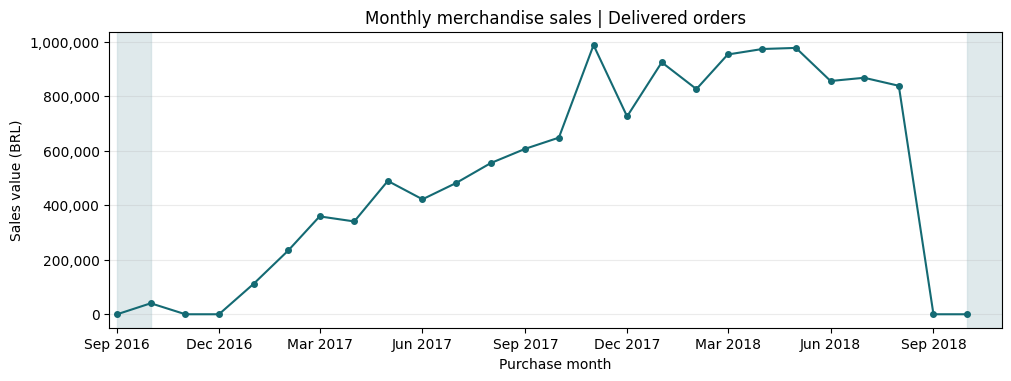

In [11]:
first_purchase = orders["order_purchase_timestamp"].min()
last_purchase = orders["order_purchase_timestamp"].max()
calendar = pd.period_range(first_purchase, last_purchase, freq="M")
sales_for_chart = monthly_sales.set_index("purchase_month")["sales_value_brl"].reindex(
    calendar.astype(str), fill_value=0,
)

fig, ax = plt.subplots(figsize=(10, 3.7), layout="constrained")
ax.plot(calendar.to_timestamp(), sales_for_chart, color="#146A73", marker="o", markersize=4)
for month in [calendar[0], calendar[-1]]:
    ax.axvspan(month.start_time, (month + 1).start_time, color="#C5D8DC", alpha=0.55)
ax.set_xlim(calendar[0].start_time - pd.Timedelta(days=7), (calendar[-1] + 1).start_time)
ax.set(title="Monthly merchandise sales | Delivered orders", xlabel="Purchase month", ylabel="Sales value (BRL)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
plt.show()

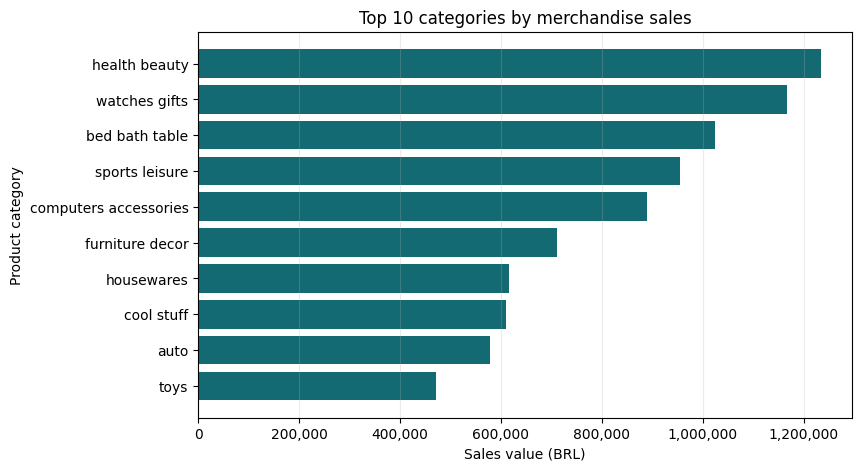

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
ax.barh(top_category_sales["category"].str.replace("_", " "), top_category_sales["sales_value_brl"],
        color="#146A73")
ax.invert_yaxis()
ax.set(title="Top 10 categories by merchandise sales", xlabel="Sales value (BRL)", ylabel="Product category")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
plt.show()

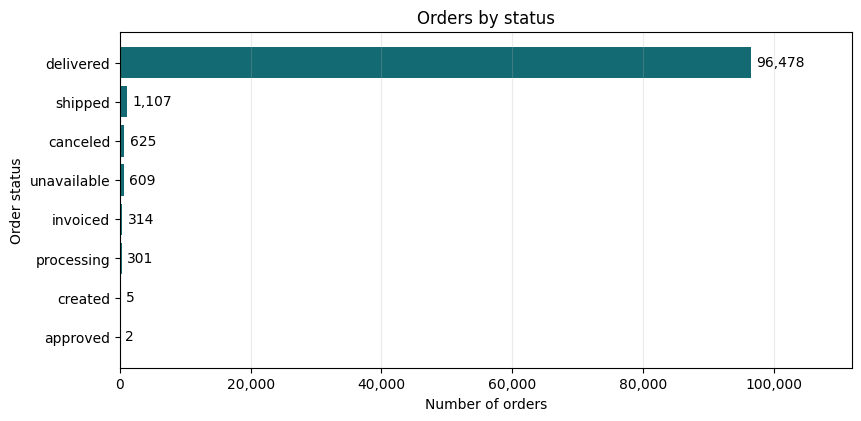

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.1), layout="constrained")
bars = ax.barh(status_counts["order_status"], status_counts["order_count"], color="#146A73")
ax.bar_label(bars, labels=[f"{count:,}" for count in status_counts["order_count"]], padding=4)
ax.invert_yaxis()
ax.margins(x=0.16)
ax.set(title="Orders by status", xlabel="Number of orders", ylabel="Order status")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
plt.show()

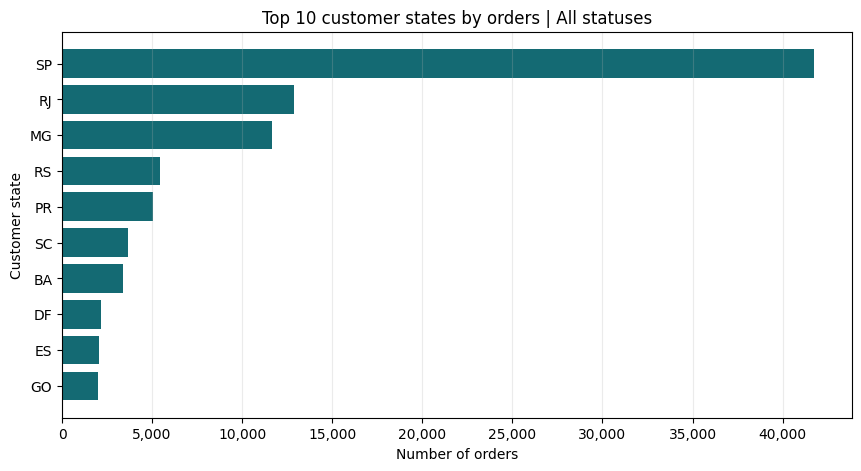

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout="constrained")
ax.barh(top_regions["customer_state"], top_regions["order_count"], color="#146A73")
ax.invert_yaxis()
ax.set(title="Top 10 customer states by orders | All statuses", xlabel="Number of orders", ylabel="Customer state")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", alpha=0.25)
plt.show()

In [15]:
peak = monthly_sales.loc[monthly_sales["sales_value_brl"].idxmax()]
sales_leader = top_category_sales.iloc[0]
volume_leader = top_category_items.iloc[0]
region_leader = top_regions.iloc[0]
display(Markdown(
    f"**Finding.** Sales peaked in {peak['purchase_month']} at BRL {peak['sales_value_brl']:,.2f}. "
    f"{sales_leader['category']} led by sales value, while {volume_leader['category']} led by item count. "
    f"{region_leader['customer_state']} led the state ranking with {region_leader['order_count']:,} orders "
    f"({region_leader['order_count'] / total_orders:.1%} of all orders)."
))

**Finding.** Sales peaked in 2017-11 at BRL 987,765.37. health_beauty led by sales value, while bed_bath_table led by item count. SP led the state ranking with 41,746 orders (42.0% of all orders).

**Вывод.** Пик пришёлся на ноябрь 2017 года (987 765,37 BRL). По стоимости лидировала категория `health_beauty`, по числу позиций - `bed_bath_table`. Штат SP лидировал по количеству заказов (41 746, или 42,0% всех заказов).